# 02 · Machine Learning, Forecasting and Recommendation Engine

## 1. Configuration

In [1]:
# !pip install -r ../requirements.txt      # <- uncomment to install dependencies from inside Jupyter

import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "outputs"
CLEAN_FILE = OUTPUT_DIR / "cleaned_jobs.csv.gz"
MODEL_DIR = OUTPUT_DIR / "model"
REC_DIR = OUTPUT_DIR / "recommendations"
for d in (MODEL_DIR, REC_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "app"))
import job_taxonomy as jt
import forecasting as fc
import recommender as rec

SEED = 42                 # every random component uses this seed
TEST_DAYS = 14            # hold-out length (two full weeks)
N_HIGH_DEMAND = 8         # how many categories count as 'high demand'
FORECAST_DAYS = 14        # Task 8 horizon
INTERVAL_LEVEL = 0.80     # empirical prediction interval
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format

if not CLEAN_FILE.exists():
    raise FileNotFoundError(f"{CLEAN_FILE} not found. Run notebook 01_Job_Market_EDA.ipynb first (it creates the cleaned data).")
jobs = pd.read_csv(CLEAN_FILE, parse_dates=["published_at", "date", "week_start"])
core = jobs[jobs["in_core_window"]]
print(f"Loaded {len(jobs):,} cleaned postings; {len(core):,} fall inside the complete-day core window "
      f"{core['date'].min():%Y-%m-%d} -> {core['date'].max():%Y-%m-%d}.")

Loaded 244,291 cleaned postings; 213,550 fall inside the complete-day core window 2024-02-19 -> 2024-03-23.



# Part A -Predict high-demand job roles

In [2]:
daily = core.groupby(["date", "category"]).size().unstack(fill_value=0)
daily.index = pd.DatetimeIndex(daily.index, freq="D")
assert daily.index.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all(), "series must be consecutive days"
train_end = len(daily) - TEST_DAYS
train_all, test_all = daily.iloc[:train_end], daily.iloc[train_end:]
print(f"Days total: {len(daily)} | train: {len(train_all)} ({train_all.index[0]:%d %b} – {train_all.index[-1]:%d %b}) "
      f"| test: {len(test_all)} ({test_all.index[0]:%d %b} – {test_all.index[-1]:%d %b})")

classified = train_all.drop(columns=jt.UNCLASSIFIED)
high_demand = classified.mean().nlargest(N_HIGH_DEMAND)
print(f"\nHigh-demand categories (mean postings/day in TRAIN period) — they cover "
      f"{high_demand.sum() / train_all.sum().sum():.0%} of all postings:")
display(high_demand.round(0).to_frame("mean_postings_per_day"))
HD = high_demand.index.tolist()
wide = daily[HD]
train, test = wide.iloc[:train_end], wide.iloc[train_end:]

Days total: 34 | train: 20 (19 Feb – 09 Mar) | test: 14 (10 Mar – 23 Mar)

High-demand categories (mean postings/day in TRAIN period) — they cover 3% of all postings:


,mean_postings_per_day
category,
Web Development & CMS,847.00
Video & Animation,629.00
Graphic Design & Branding,608.00
"Marketing, SEO & Social Media",555.00
Software Development,353.00
Writing & Content,308.00
E-commerce & Marketplaces,308.00
Mobile App Development,280.00


## A1. Models compared
| Model | Idea | Why included |
|---|---|---|
| **Seasonal naive** (baseline) | each day = same weekday last week | the benchmark every model must beat |
| **Holt-Winters** (additive) | smoothed level + weekly pattern | classic exponential smoothing for seasonal counts |
| **Holt-Winters, damped trend** | adds a trend that fades out | tests whether a trend helps |
| **Pooled Random Forest** | one forest for all categories; features = weekday, category, last week's value, trailing 7-day mean; **recursive** prediction | a machine-learning alternative; uses only information available at forecast time |

Metrics: **MAE** (average error in postings/day), **RMSE** (penalises big misses) and **MAPE** (% error; meaningful here because each category
has hundreds of postings per day). **Classification accuracy is not used** — this is a continuous forecasting problem.

In [3]:
fc_test = fc.forecast_all_models(train, h=TEST_DAYS, seed=SEED)
rows = []
for model, pred in fc_test.items():
    pred = pred.reindex(test.index)
    rows.append({"model": model, **fc.score(test.values.ravel(), pred.values.ravel())})
test_scores = pd.DataFrame(rows).set_index("model")
test_scores["MAE_skill_vs_naive_%"] = 100 * (1 - test_scores["MAE"] / test_scores.loc["Seasonal naive", "MAE"])
print("HOLD-OUT (last 14 days), all high-demand categories pooled:")
display(test_scores)

per_cat = pd.DataFrame({m: {c: fc.mae(test[c], p[c]) for c in HD} for m, p in fc_test.items()})
print("MAE per category (postings/day):")
display(per_cat)

HOLD-OUT (last 14 days), all high-demand categories pooled:


,MAE,RMSE,MAPE_%,MAE_skill_vs_naive_%
model,,,,
Seasonal naive,26.42,36.31,6.27,0.00
Holt-Winters,27.65,37.06,7.21,-4.65
Holt-Winters (damped),30.28,40.66,7.64,-14.60
Pooled Random Forest,27.35,35.04,6.63,-3.52


MAE per category (postings/day):


,Seasonal naive,Holt-Winters,Holt-Winters (damped),Pooled Random Forest
Web Development & CMS,37.07,30.55,34.30,38.86
Video & Animation,30.43,31.45,45.16,29.87
Graphic Design & Branding,32.43,32.65,31.46,36.45
"Marketing, SEO & Social Media",34.07,31.10,33.16,32.76
Software Development,8.79,11.64,12.40,8.19
Writing & Content,23.79,49.17,50.25,31.71
E-commerce & Marketplaces,27.50,19.11,19.33,20.91
Mobile App Development,17.29,15.51,16.16,20.04


**Reading the table.** "Skill vs naive" is the % reduction in MAE relative to the baseline (positive = better than baseline, negative = worse).

## A2. Actual vs predicted

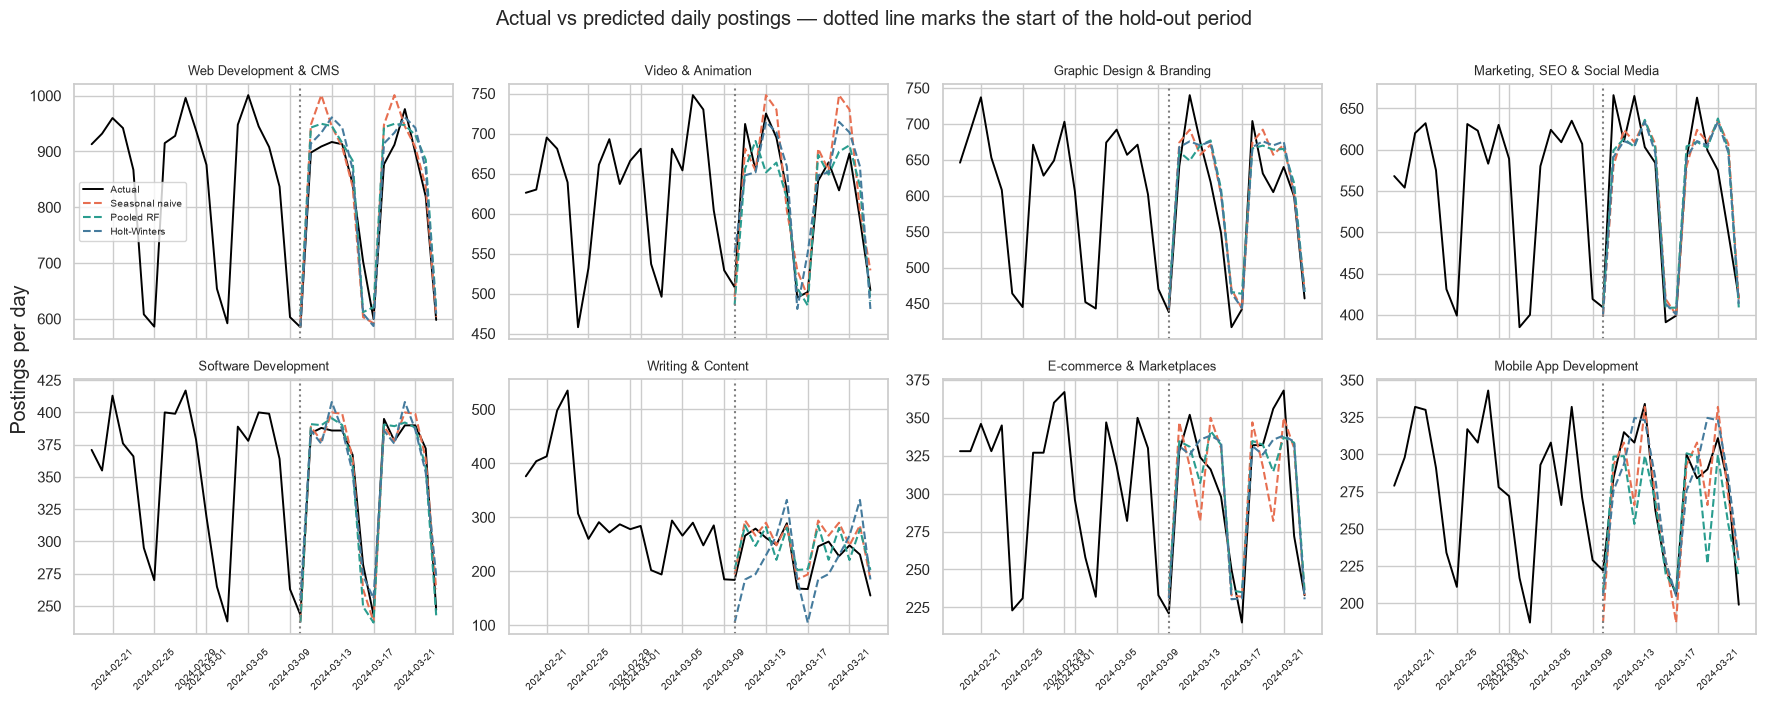

In [4]:
best_test = test_scores["MAE"].idxmin()
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for ax, c in zip(axes.ravel(), HD):
    ax.plot(wide.index, wide[c], color="black", lw=1.4, label="Actual")
    ax.plot(test.index, fc_test["Seasonal naive"][c], "--", color="#e76f51", label="Seasonal naive")
    ax.plot(test.index, fc_test["Pooled Random Forest"][c], "--", color="#2a9d8f", label="Pooled RF")
    ax.plot(test.index, fc_test["Holt-Winters"][c], "--", color="#457b9d", label="Holt-Winters")
    ax.axvline(test.index[0], color="grey", ls=":")
    ax.set_title(c, fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Actual vs predicted daily postings — dotted line marks the start of the hold-out period", y=1.0)
fig.supylabel("Postings per day"); plt.tight_layout(); plt.show()

## A3. Robust model selection: rolling-origin backtest
A single 14-day hold-out is a small sample (2 weekends). To choose a model more reliably *without peeking at the test set*, we also run an
**expanding-window backtest**: repeatedly train on the first *k* days (k = 14, 15, 16, 17 — the training period holds only 20 days) and predict the following days up to the end of the **training** period (so horizons are 6, 5, 4 and 3 days; no test day is touched).
Selection uses these backtest errors; the hold-out above is then a genuinely independent check.

In [5]:
origins = [14, 15, 16, 17]                   # training period has only 20 days: horizons are truncated at its end (6, 5, 4, 3 days)
assert max(origins) < len(train), "backtest origins must lie inside the training period"
assert train.index.max() < test.index.min(), "no test day may be used for model selection"
bt = fc.rolling_origin_backtest(train, origins=origins, horizon=7, seed=SEED)
bt_scores = bt.groupby("model").apply(lambda g: pd.Series(fc.score(g["actual"], g["pred"])), include_groups=False)
bt_scores["MAE_skill_vs_naive_%"] = 100 * (1 - bt_scores["MAE"] / bt_scores.loc["Seasonal naive", "MAE"])
bt_scores["n_forecasts"] = bt.groupby("model").size()
print(f"Rolling-origin backtest inside the training period ({len(origins)} origins, horizons truncated at the end of training, {len(HD)} categories):")
display(bt_scores)

# selection rule: lowest backtest MAE; if a more complex model is within 3% of the baseline, keep the simpler one
best_bt = bt_scores["MAE"].idxmin()
complexity = {"Seasonal naive": 0, "Holt-Winters": 1, "Holt-Winters (damped)": 2, "Pooled Random Forest": 3}
simpler_ok = bt_scores.loc["Seasonal naive", "MAE"] <= bt_scores.loc[best_bt, "MAE"] * 1.03
SELECTED = "Seasonal naive" if simpler_ok else best_bt
print(f"\nBest backtest model: {best_bt} | selected (parsimony rule, 3% tolerance): {SELECTED}")
print("Hold-out check of the selected model:", {k: round(v, 2) for k, v in test_scores.loc[SELECTED, ["MAE", "RMSE", "MAPE_%"]].items()})

Rolling-origin backtest inside the training period (4 origins, horizons truncated at the end of training, 8 categories):


,MAE,RMSE,MAPE_%,MAE_skill_vs_naive_%,n_forecasts
model,,,,,
Holt-Winters,36.94,51.79,9.52,-24.97,144
Holt-Winters (damped),37.10,51.02,9.48,-25.52,144
Pooled Random Forest,32.98,40.55,7.64,-11.57,144
Seasonal naive,29.56,39.00,6.63,0.00,144



Best backtest model: Seasonal naive | selected (parsimony rule, 3% tolerance): Seasonal naive
Hold-out check of the selected model: {'MAE': 26.42, 'RMSE': 36.31, 'MAPE_%': 6.27}


## A4. Did we predict the *high-demand roles* correctly?
Beyond counts, the practical question is the **ranking**: do the categories forecast to be busiest turn out to be the busiest? We compare the predicted vs actual
ranking over the 14 test days (overlap of the top-5 sets and Spearman rank correlation).

In [6]:
pred_total = fc_test[SELECTED].reindex(test.index).sum()
act_total = test.sum()
top5_pred, top5_act = set(pred_total.nlargest(5).index), set(act_total.nlargest(5).index)
rho, _ = stats.spearmanr(pred_total, act_total)
rank_tbl = pd.DataFrame({"actual_postings": act_total, "predicted_postings": pred_total.round(0),
                         "error_%": 100 * (pred_total - act_total) / act_total,
                         "actual_rank": act_total.rank(ascending=False).astype(int),
                         "predicted_rank": pred_total.rank(ascending=False).astype(int)}).sort_values("actual_rank")
display(rank_tbl)
print(f"Top-5 overlap: {len(top5_pred & top5_act)}/5 | Spearman rank correlation of 14-day totals: {rho:.2f}")

,actual_postings,predicted_postings,error_%,actual_rank,predicted_rank
Web Development & CMS,11447,"11,668.00",1.93,1,1
Video & Animation,8626,"8,884.00",2.99,2,2
Graphic Design & Branding,8156,"8,418.00",3.21,3,3
"Marketing, SEO & Social Media",7673,"7,748.00",0.98,4,4
Software Development,4851,"4,862.00",0.23,5,5
E-commerce & Marketplaces,4197,"4,184.00",-0.31,6,6
Mobile App Development,3818,"3,772.00",-1.20,7,7
Writing & Content,3227,"3,524.00",9.20,8,8


Top-5 overlap: 5/5 | Spearman rank correlation of 14-day totals: 1.00


### A5. conclusions
* Demand is dominated by a stable group of categories whose **day-to-day pattern is mostly the weekly cycle**; the seasonal-naive baseline already captures most of it.
* The selected model and its errors are in the tables above (nothing is hand-written). In the run shipped with this project the **seasonal-naive baseline wins** on both the backtest and the hold-out. If a "fancier" model fails to beat the baseline, that is a *finding*,
  not a failure: with ~20 training days per series there is not enough signal for models with many parameters.
* The ranking of roles is predicted well because category sizes differ by large margins and change slowly.
* **Limits:** only 2 weekends are in the hold-out; one unusual week would change the numbers; the categories are keyword-derived.


# Part B- Predict future job-market trends

## B1. Forecast total postings and the high-demand categories

In [7]:
full_total = core.groupby("date").size().rename("Total").to_frame()
full_total.index = pd.DatetimeIndex(full_total.index, freq="D")
bt_total = fc.rolling_origin_backtest(full_total, origins=[14, 17, 20, 23, 26], horizon=7, seed=SEED)
bt_cat_all = fc.rolling_origin_backtest(wide, origins=[14, 17, 20, 23, 26], horizon=7, seed=SEED)

fc_total = fc.forecast_all_models(full_total, FORECAST_DAYS, seed=SEED)[SELECTED]["Total"]
fc_cats = fc.forecast_all_models(wide, FORECAST_DAYS, seed=SEED)[SELECTED]
lo_t, hi_t = fc.ratio_interval(bt_total, SELECTED, INTERVAL_LEVEL)
lo_c, hi_c = fc.ratio_interval(bt_cat_all, SELECTED, INTERVAL_LEVEL)
print(f"Selected model: {SELECTED}.  {INTERVAL_LEVEL:.0%} empirical ratio interval — total: x{lo_t:.2f} … x{hi_t:.2f}; per category: x{lo_c:.2f} … x{hi_c:.2f}")

total_fc = pd.DataFrame({"baseline": fc_total, "lower": fc_total * lo_t, "upper": fc_total * hi_t})
display(total_fc.round(0).assign(weekday=total_fc.index.day_name()))

Selected model: Seasonal naive.  80% empirical ratio interval — total: x0.96 … x1.01; per category: x0.90 … x1.10


,baseline,lower,upper,weekday
2024-03-24,"4,452.00","4,294.00","4,490.00",Sunday
2024-03-25,"6,799.00","6,558.00","6,856.00",Monday
2024-03-26,"6,897.00","6,653.00","6,955.00",Tuesday
2024-03-27,"6,819.00","6,578.00","6,877.00",Wednesday
2024-03-28,"6,800.00","6,559.00","6,857.00",Thursday
2024-03-29,"6,195.00","5,976.00","6,247.00",Friday
2024-03-30,"4,515.00","4,355.00","4,553.00",Saturday
2024-03-31,"4,452.00","4,294.00","4,490.00",Sunday
2024-04-01,"6,799.00","6,558.00","6,856.00",Monday
2024-04-02,"6,897.00","6,653.00","6,955.00",Tuesday


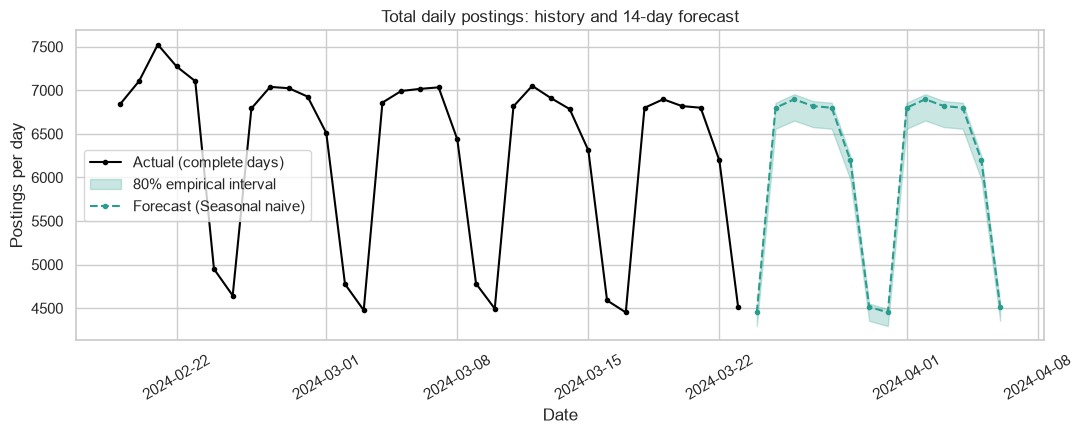

In [8]:
hist = full_total["Total"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(hist.index, hist.values, "o-", color="black", ms=3, label="Actual (complete days)")
ax.fill_between(total_fc.index, total_fc["lower"], total_fc["upper"], alpha=0.25, color="#2a9d8f", label=f"{INTERVAL_LEVEL:.0%} empirical interval")
ax.plot(total_fc.index, total_fc["baseline"], "o--", color="#2a9d8f", ms=3, label=f"Forecast ({SELECTED})")
ax.set_title("Total daily postings: history and 14-day forecast"); ax.set_xlabel("Date"); ax.set_ylabel("Postings per day"); ax.legend()
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Caution when reading these intervals.**
* The selected seasonal-naive model simply **repeats last week's pattern**, so the forecast is flat from week to week by construction.
* The total-volume interval is **narrow and asymmetric**: in the backtest the baseline slightly *over*-predicted (volume drifted down ~2–4 % per week), so most past ratios are
  below 1. With only five forecast origins this interval is **probably too optimistic**; treat it as a lower bound on the true uncertainty, not as a guarantee.
* Category intervals are wider because individual categories are noisier than the total.

### B1b. A genuine out-of-sample spot check
The last day in the file (Sunday 24 Mar) was **partial** (data end at 14:16 UTC), so it was excluded from training. We can still compare it with the forecast:
we estimate what share of a typical Sunday's postings arrives by 14:16 UTC from earlier Sundays and scale the observed count accordingly. It is a *single, rough* check.

In [9]:
last_day = jobs[jobs["date"] == jobs["date"].max()]
last_ts = last_day["published_at"].max()
sundays = core[core["weekday"] == "Sunday"]
frac_by_cut = np.mean([((g["published_at"].dt.hour * 60 + g["published_at"].dt.minute) <= last_ts.hour * 60 + last_ts.minute).mean()
                       for _, g in sundays.groupby("date")])
est_full = len(last_day) / frac_by_cut
print(f"Observed on {last_day['date'].iloc[0]:%d %b} until {last_ts:%H:%M} UTC: {len(last_day):,} postings "
      f"(typically {frac_by_cut:.0%} of a Sunday) -> implied full-day ≈ {est_full:,.0f}")
print(f"Forecast for that day: {total_fc['baseline'].iloc[0]:,.0f}  (interval {total_fc['lower'].iloc[0]:,.0f} – {total_fc['upper'].iloc[0]:,.0f})"
      f" -> {'inside' if total_fc['lower'].iloc[0] <= est_full <= total_fc['upper'].iloc[0] else 'outside'} the interval")

Observed on 24 Mar until 14:16 UTC: 2,180 postings (typically 50% of a Sunday) -> implied full-day ≈ 4,362
Forecast for that day: 4,452  (interval 4,294 – 4,490) -> inside the interval


## B2. Category forecasts (next 14 days)

,last_14d_actual,next_14d_forecast,lower_80,upper_80,change_%
Web Development & CMS,11447,"11,360.00","10,259.00","12,454.00",-1.00
Video & Animation,8626,"8,416.00","7,600.00","9,227.00",-2.00
Graphic Design & Branding,8156,"8,156.00","7,366.00","8,942.00",0.00
"Marketing, SEO & Social Media",7673,"7,490.00","6,764.00","8,211.00",-2.00
Software Development,4851,"4,830.00","4,362.00","5,295.00",-0.00
E-commerce & Marketplaces,4197,"4,216.00","3,807.00","4,622.00",0.00
Mobile App Development,3818,"3,738.00","3,376.00","4,098.00",-2.00
Writing & Content,3227,"3,060.00","2,763.00","3,355.00",-5.00


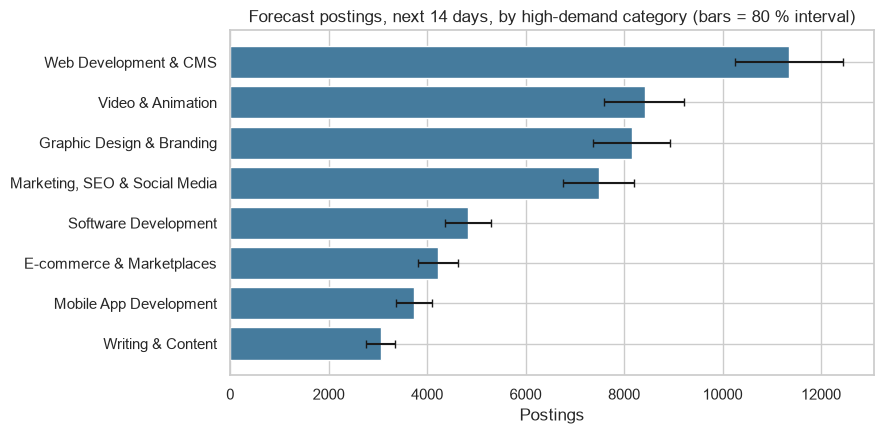

In [10]:
cat_fc = pd.DataFrame({"last_14d_actual": wide.iloc[-14:].sum(), "next_14d_forecast": fc_cats.sum(),
                       "lower_80": fc_cats.sum() * lo_c, "upper_80": fc_cats.sum() * hi_c})
cat_fc["change_%"] = 100 * (cat_fc["next_14d_forecast"] / cat_fc["last_14d_actual"] - 1)
cat_fc = cat_fc.sort_values("next_14d_forecast", ascending=False)
display(cat_fc.round(0))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(cat_fc))
ax.barh(y, cat_fc["next_14d_forecast"], color="#457b9d",
        xerr=[cat_fc["next_14d_forecast"] - cat_fc["lower_80"], cat_fc["upper_80"] - cat_fc["next_14d_forecast"]], capsize=3)
ax.set_yticks(y); ax.set_yticklabels(cat_fc.index); ax.invert_yaxis()
ax.set_title("Forecast postings, next 14 days, by high-demand category (bars = 80 % interval)"); ax.set_xlabel("Postings")
plt.tight_layout(); plt.show()

## B3. Scenarios (illustrative sensitivity analysis- *not* predictions)
Scenarios answer "what if the level drifts?". We scale the **baseline forecast** by a multiplier that ramps linearly from 0 to ±*g* over the horizon, where *g* equals **one standard deviation
of the observed week-over-week change** in total volume (floored at 3 %). They are assumptions anchored to observed variability, **not** forecasts of what will happen, and they carry
no probability.

Week-over-week % changes in total postings (full weeks): [-4.2, 0.2, -1.6] -> scenario drift g = ±3.0%


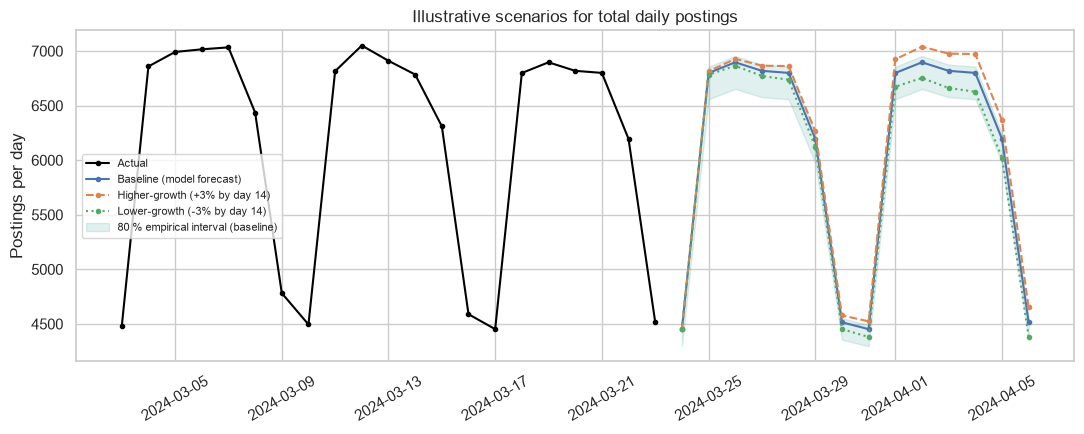

,total postings over 14 days
Baseline (model forecast),"84,954.00"
Higher-growth (+3% by day 14),"86,223.00"
Lower-growth (-3% by day 14),"83,685.00"


In [11]:
wk_tot = core[core["week_start"].isin(core.groupby("week_start")["date"].nunique().loc[lambda s: s == 7].index)].groupby("week_start").size()
wow = wk_tot.pct_change().dropna()
g = max(float(wow.std(ddof=1)) if len(wow) > 1 else 0.0, 0.03)
print("Week-over-week % changes in total postings (full weeks):", (100 * wow).round(1).tolist(), f"-> scenario drift g = ±{g:.1%}")
ramp = np.linspace(0, 1, FORECAST_DAYS)
scen = pd.DataFrame({"Baseline (model forecast)": total_fc["baseline"].values,
                     f"Higher-growth (+{g:.0%} by day {FORECAST_DAYS})": total_fc["baseline"].values * (1 + g * ramp),
                     f"Lower-growth (-{g:.0%} by day {FORECAST_DAYS})": total_fc["baseline"].values * (1 - g * ramp)}, index=total_fc.index)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(hist.index[-21:], hist.values[-21:], "o-", color="black", ms=3, label="Actual")
for col, style in zip(scen.columns, ["-", "--", ":"]):
    ax.plot(scen.index, scen[col], style, marker="o", ms=3, label=col)
ax.fill_between(total_fc.index, total_fc["lower"], total_fc["upper"], alpha=0.15, color="#2a9d8f", label="80 % empirical interval (baseline)")
ax.set_title("Illustrative scenarios for total daily postings"); ax.set_ylabel("Postings per day"); ax.legend(fontsize=8); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()
display(scen.sum().round(0).to_frame("total postings over 14 days"))

## B4. Uncertainty, bias and interpretation
* **Seasonality.** Only the **weekly** cycle is observable. Annual patterns (e.g. January hiring surges, summer slowdowns) cannot be estimated from 5 weeks; forecasts beyond a couple
  of weeks would be guesswork.
* **Short history.** 34 days → at most 4–5 repetitions of the weekly pattern; intervals come from a handful of backtest folds and are themselves uncertain.
* **Dataset bias.** One platform (Upwork), one scraping method (with outages), titles only, and *postings*, not hires. Platform changes, scraper changes or a news-driven spike
  would all move the series without any change in the broader labour market.
* **Derived categories.** Keyword rules misassign some postings; category forecasts inherit that noise.
* **Predictive ≠ causal.** These models extrapolate patterns; they do **not** explain *why* demand moves, and no policy or causal claim should be drawn from them.
* **Scenarios** are sensitivity illustrations, not forecasts with probabilities.

Forecasts are saved for the dashboard in Notebook 3.

In [12]:
total_fc.rename_axis("date").to_csv(MODEL_DIR / "forecast_total_daily.csv")
cat_fc.rename_axis("category").to_csv(MODEL_DIR / "forecast_categories_14d.csv")
fc_cats.rename_axis("date").to_csv(MODEL_DIR / "forecast_categories_daily.csv")
scen.rename_axis("date").to_csv(MODEL_DIR / "forecast_scenarios.csv")
pd.concat({"holdout": test_scores, "rolling_backtest": bt_scores}).to_csv(MODEL_DIR / "model_comparison.csv")
with open(MODEL_DIR / "model_meta.json", "w") as f:
    json.dump({"selected_model": SELECTED, "interval_level": INTERVAL_LEVEL, "ratio_total": [lo_t, hi_t], "ratio_category": [lo_c, hi_c],
               "train_days": len(train), "test_days": len(test), "high_demand_categories": HD,
               "last_complete_day": str(core["date"].max().date()), "seed": SEED}, f, indent=2)
print("Saved model outputs:", sorted(p.name for p in MODEL_DIR.iterdir()))

Saved model outputs: ['forecast_categories_14d.csv', 'forecast_categories_daily.csv', 'forecast_scenarios.csv', 'forecast_total_daily.csv', 'model_comparison.csv', 'model_meta.json']



# Part C -Personalised job-recommendation engine

## C1. Design

In [13]:
t0 = pd.Timestamp.now()
recommender = rec.JobRecommender(jobs, weights=None)       # fits TF-IDF once; reused for every query
print(f"Index built in {(pd.Timestamp.now() - t0).total_seconds():.1f}s | postings: {len(recommender.jobs):,} | vocabulary: {len(recommender.vectorizer.vocabulary_):,} terms")
print("Reference date (newest posting):", recommender.reference_date)

Index built in 4.6s | postings: 244,291 | vocabulary: 65,123 terms
Reference date (newest posting): 2024-03-24 14:16:47+00:00


## C2. Sample user profiles and recommendations
Real postings from the dataset, with their original Upwork URLs. (Links point to the live site; a posting from early 2024 may no longer be open.)

In [14]:
def show(result, n_explain=3):
    """Compact table of recommendations + the explanation for the first few."""
    recs = result["recommendations"]
    if not recs:
        print("No recommendations.", result["warnings"]); return
    table = pd.DataFrame([{"rank": r["rank"], "score": r["score"], "job_title": r["job_title"], "company": r["company"],
                           "location (client)": r["location"], "pay": r["pay"], "work_mode": "Remote (platform)",
                           "relevant_skills": ", ".join(r["relevant_skills"]) or "-", "url": r["url"]} for r in recs])
    print(f"{result['n_candidates']:,} postings passed the filters; showing top {len(recs)}. Weights used: {result['weights_used']}")
    for w in result["warnings"]:
        print("WARNING:", w)
    display(table)
    for r in recs[:n_explain]:
        print(f"\n#{r['rank']} {r['job_title']}  (score {r['score']}; breakdown {r['score_breakdown']})")
        for line in r["why_recommended"]:
            print("   -", line)

profile_1 = {"role": "video editor", "skills": ["youtube", "premiere pro", "motion graphics"], "country": "United States",
             "employment_type": "hourly", "min_hourly_rate": 20, "work_mode": "remote", "experience_level": "senior", "top_k": 8}
print("PROFILE 1:", json.dumps(profile_1))
res_1 = recommender.recommend(profile_1)
show(res_1)

PROFILE 1: {"role": "video editor", "skills": ["youtube", "premiere pro", "motion graphics"], "country": "United States", "employment_type": "hourly", "min_hourly_rate": 20, "work_mode": "remote", "experience_level": "senior", "top_k": 8}
3,465 postings passed the filters; showing top 8. Weights used: {'text': 0.7, 'recency': 0.1, 'pay': 0.1, 'soft': 0.1}


,rank,score,job_title,company,location (client),pay,work_mode,relevant_skills,url
0,1,0.62,Video editor,None,United States,$40-$60/hr,Remote (platform),-,https://www.upwork.com/jobs/Video-editor_%7E01...
1,2,0.49,Video Editor for,None,United States,pay not disclosed,Remote (platform),-,https://www.upwork.com/jobs/Video-Editor-for_%...
2,3,0.48,Looking for a #corecore video editor,None,United States,$30-$40/hr,Remote (platform),-,https://www.upwork.com/jobs/Looking-for-coreco...
3,4,0.48,Inshot video editor,None,United States,pay not disclosed,Remote (platform),-,https://www.upwork.com/jobs/Inshot-video-edito...
4,5,0.47,Video editor needed,None,United States,$30-$50/hr,Remote (platform),-,https://www.upwork.com/jobs/Video-editor-neede...
5,6,0.46,YouTube Video Editor,None,United States,$10-$40/hr,Remote (platform),youtube,https://www.upwork.com/jobs/YouTube-Video-Edit...
6,7,0.43,Experienced Video Editor Needed,None,United States,$12-$40/hr,Remote (platform),-,https://www.upwork.com/jobs/Experienced-Video-...
7,8,0.42,Video Editor for YouTube,None,United States,$10-$40/hr,Remote (platform),youtube,https://www.upwork.com/jobs/Video-Editor-for-Y...



#1 Video editor  (score 0.6167; breakdown {'text': 0.6, 'recency': 0.9672, 'pay': 1.0, 'soft': 0.0})
   - Title text similarity 0.60 (shared keywords: editor, video).
   - Client country United States matches your preference.
   - Pay: $40-$60/hr
   - Employment type matches: Hourly.
   - Posted 0.5 days before the newest posting in the data.

#2 Video Editor for  (score 0.4889; breakdown {'text': 0.6, 'recency': 0.4392, 'pay': 0.25, 'soft': 0.0})
   - Title text similarity 0.60 (shared keywords: editor, video).
   - Client country United States matches your preference.
   - Pay: pay not disclosed - minimum could not be verified.
   - Employment type matches: Hourly.
   - Posted 11.5 days before the newest posting in the data.

#3 Looking for a #corecore video editor  (score 0.4847; breakdown {'text': 0.5214, 'recency': 0.3226, 'pay': 0.875, 'soft': 0.0})
   - Title text similarity 0.52 (shared keywords: editor, video).
   - Client country United States matches your preference.
   - P

In [15]:
profile_2 = {"role": "data analyst", "skills": "python, sql, power bi, excel", "employment_type": "fixed_price", "min_fixed_budget": 300, "top_k": 8}
print("PROFILE 2:", json.dumps(profile_2))
res_2 = recommender.recommend(profile_2)
show(res_2, n_explain=2)

PROFILE 2: {"role": "data analyst", "skills": "python, sql, power bi, excel", "employment_type": "fixed_price", "min_fixed_budget": 300, "top_k": 8}
985 postings passed the filters; showing top 8. Weights used: {'text': 0.778, 'recency': 0.111, 'pay': 0.111}


,rank,score,job_title,company,location (client),pay,work_mode,relevant_skills,url
0,1,0.61,Data Analyst,None,United States,"$12,000 fixed price",Remote (platform),-,https://www.upwork.com/jobs/Data-Analyst_%7E01...
1,2,0.47,AI Engineer cum Data Analyst,None,India,"$2,000 fixed price",Remote (platform),-,https://www.upwork.com/jobs/Engineer-cum-Data-...
2,3,0.45,Data analyst/research writer,None,Germany,"$1,600 fixed price",Remote (platform),-,https://www.upwork.com/jobs/Data-analyst-resea...
3,4,0.44,YouTube Data Analyst,None,United Kingdom,"$1,500 fixed price",Remote (platform),-,https://www.upwork.com/jobs/YouTube-Data-Analy...
4,5,0.42,Business Data Analyst,None,NaN,$500 fixed price,Remote (platform),-,https://www.upwork.com/jobs/Business-Data-Anal...
5,6,0.40,Data Analyst - Tableau and SQL,None,United States,$500 fixed price,Remote (platform),sql,https://www.upwork.com/jobs/Data-Analyst-Table...
6,7,0.40,Data Analyst/BI Expert to integrate & analyze ...,None,Spain,"$2,067 fixed price",Remote (platform),power bi,https://www.upwork.com/jobs/Data-Analyst-Exper...
7,8,0.38,Data Analyst Training Instructor,None,United States,$400 fixed price,Remote (platform),-,https://www.upwork.com/jobs/Data-Analyst-Train...



#1 Data Analyst  (score 0.6131; breakdown {'text': 0.6, 'recency': 0.3183, 'pay': 1.0})
   - Title text similarity 0.60 (shared keywords: analyst, data).
   - Pay: $12,000 fixed price
   - Employment type matches: Fixed price.
   - Posted 16.0 days before the newest posting in the data.

#2 AI Engineer cum Data Analyst  (score 0.4691; breakdown {'text': 0.334, 'recency': 0.8846, 'pay': 1.0})
   - Title text similarity 0.33 (shared keywords: analyst, data).
   - Pay: $2,000 fixed price
   - Employment type matches: Fixed price.
   - Posted 1.7 days before the newest posting in the data.


In [16]:
profile_3 = {"role": "chatbot developer", "skills": ["openai", "python"], "country": ["India", "Pakistan"], "min_hourly_rate": 15, "top_k": 6}
print("PROFILE 3:", json.dumps(profile_3))
res_3 = recommender.recommend(profile_3)
show(res_3, n_explain=2)

PROFILE 3: {"role": "chatbot developer", "skills": ["openai", "python"], "country": ["India", "Pakistan"], "min_hourly_rate": 15, "top_k": 6}
1,000 postings passed the filters; showing top 6. Weights used: {'text': 0.778, 'recency': 0.111, 'pay': 0.111}


,rank,score,job_title,company,location (client),pay,work_mode,relevant_skills,url
0,1,0.48,WhatsApp chatbot developer,None,India,$30-$60/hr,Remote (platform),-,https://www.upwork.com/jobs/WhatsApp-chatbot-d...
1,2,0.47,Chatbot developer Required,None,India,$15-$35/hr,Remote (platform),-,https://www.upwork.com/jobs/Chatbot-developer-...
2,3,0.40,WhatsApp AI Chatbot Developer,None,India,pay not disclosed,Remote (platform),-,https://www.upwork.com/jobs/WhatsApp-Chatbot-D...
3,4,0.37,Need an Open AI/Azure Chatbot Developer,None,Pakistan,$20-$40/hr,Remote (platform),-,https://www.upwork.com/jobs/Need-Open-Azure-Ch...
4,5,0.35,I Need an Open AI WhatsApp Chatbot Developer,None,Pakistan,$18-$80/hr,Remote (platform),-,https://www.upwork.com/jobs/Need-Open-WhatsApp...
5,6,0.33,Palantir Developer,None,India,$25-$50/hr,Remote (platform),-,https://www.upwork.com/jobs/Palantir-Developer...



#1 WhatsApp chatbot developer  (score 0.4762; breakdown {'text': 0.4109, 'recency': 0.4099, 'pay': 1.0})
   - Title text similarity 0.41 (shared keywords: chatbot, developer).
   - Client country India matches your preference.
   - Pay: $30-$60/hr
   - Posted 12.5 days before the newest posting in the data.

#2 Chatbot developer Required  (score 0.4696; breakdown {'text': 0.4714, 'recency': 0.0928, 'pay': 0.8333})
   - Title text similarity 0.47 (shared keywords: chatbot, developer).
   - Client country India matches your preference.
   - Pay: $15-$35/hr
   - Posted 33.3 days before the newest posting in the data.


## C3. Input validation and edge cases
The same validation is used by the REST API in Notebook 3 (invalid input → HTTP 400 with all problems listed at once).

In [17]:
bad_inputs = {"empty request": {}, "wrong types": {"role": 123, "skills": {"a": 1}},
              "bad enums / ranges": {"role": "logo design", "employment_type": "contract", "top_k": 100, "min_hourly_rate": -5},
              "conflicting filters": {"role": "logo design", "employment_type": "fixed_price", "min_hourly_rate": 20},
              "unknown field": {"role": "logo design", "salary": 50}}
for name, payload in bad_inputs.items():
    try:
        rec.validate_preferences(payload); print(name, "-> accepted (unexpected)")
    except rec.ValidationError as e:
        print(f"{name:22s}-> {e.errors}")
print()
print("Nonsense query:", recommender.recommend({"role": "qwxzv"})["warnings"])
print("Filter that is too strict:", recommender.recommend({"role": "logo design", "country": "Antarctica"})["warnings"])

empty request         -> ["Provide at least one of 'role' or 'skills'."]
wrong types           -> ["'role' must be a string.", "'skills' must be a string (comma-separated) or a list of strings."]
bad enums / ranges    -> ["'employment_type' must be one of ['any', 'fixed_price', 'hourly']; got 'contract'.", "'min_hourly_rate' must be a non-negative number.", "'top_k' must be an integer between 1 and 20."]
conflicting filters   -> ["'min_hourly_rate' conflicts with employment_type='fixed_price'."]
unknown field         -> ["Unknown field(s): ['salary']. Allowed fields: ['country', 'employment_type', 'experience_level', 'include_undisclosed_pay', 'max_age_days', 'min_fixed_budget', 'min_hourly_rate', 'role', 'skills', 'strict_country', 'top_k', 'work_mode']."]

Nonsense query: ['No postings match your text query and filters. Try fewer filters or broader keywords.']
Filter that is too strict: ['No postings match your text query and filters. Try fewer filters or broader keywords.']


## C4. How good are the recommendations? (evaluation and its limits)
**There are no ground-truth labels** (no user clicks, applications or relevance judgements), so *true* ranking metrics such as NDCG against human relevance **cannot** be computed.
What we can do is a **proxy test** — clearly weaker, and partly circular because categories come from the same title keywords:

* Take 300 random postings as pseudo-users. Query = the posting's title with **one word removed** (to avoid trivially retrieving itself).
* A returned job counts as *relevant* if it has the **same derived category** as the seed.
* Report Precision@10, MRR (rank of the first relevant result), and **hit@10** = the seed's own title (or an identical one) appears in the top 10.
* Compare with a **random baseline** (expected precision if we picked random postings) and a **most-recent baseline**.

Passing this test shows that the engine retrieves topically coherent results; it does **not** show that real job seekers would find them useful.

In [18]:
rng = np.random.default_rng(SEED)
pool = jobs[(jobs["category"] != jt.UNCLASSIFIED) & (jobs["title_tokens"].fillna("").str.split().str.len() >= 3)]
seeds = pool.sample(300, random_state=SEED)
p_at_k, rr, hit = [], [], []
for _, s in seeds.iterrows():
    toks = s["title_tokens"].split()
    drop = int(rng.integers(len(toks)))
    query = " ".join(t for i, t in enumerate(toks) if i != drop)
    out = recommender.recommend({"role": query, "top_k": 10})["recommendations"]
    if not out:
        p_at_k.append(0.0); rr.append(0.0); hit.append(0.0); continue
    rel = [r["category"] == s["category"] for r in out]
    p_at_k.append(np.mean(rel))
    rr.append(next((1 / (i + 1) for i, x in enumerate(rel) if x), 0.0))
    seed_norm = s["title_norm"]
    hit.append(float(any(jt.normalize_title(r["job_title"]) == seed_norm for r in out)))

cat_p = jobs["category"].value_counts(normalize=True)
random_precision = float((seeds["category"].map(cat_p)).mean())          # chance a random posting shares the seed's category
recent = jobs.sort_values("published_at", ascending=False).head(10)
recent_precision = float(np.mean([(recent["category"] == c).mean() for c in seeds["category"]]))
eval_tbl = pd.DataFrame({"Content-based (TF-IDF)": {"Precision@10 (same category)": np.mean(p_at_k), "MRR": np.mean(rr), "Hit@10 (seed title retrieved)": np.mean(hit)},
                         "Random baseline": {"Precision@10 (same category)": random_precision, "MRR": np.nan, "Hit@10 (seed title retrieved)": np.nan},
                         "Most-recent baseline": {"Precision@10 (same category)": recent_precision, "MRR": np.nan, "Hit@10 (seed title retrieved)": np.nan}})
display(eval_tbl)

,Content-based (TF-IDF),Random baseline,Most-recent baseline
Precision@10 (same category),0.58,0.07,0.08
MRR,0.91,NaN,NaN
Hit@10 (seed title retrieved),0.85,NaN,NaN


**Interpretation.** The engine is far above both baselines on topical coherence — expected for a keyword-based method evaluated with keyword-derived labels, hence only a *sanity check*. A real
evaluation needs human relevance judgements or user interaction logs (e.g., A/B tests with click-through or application rates).

## C5. Limitations of the recommender
* Matches **titles only**; two postings with different words but the same meaning (e.g. "copywriter" vs "content writer") are only linked through shared words. Embedding models could help but need
  more justification/compute; TF-IDF was chosen as an interpretable baseline.
* No description, skills, company or experience fields exist; those preferences act only as weak title hints (the API reports this in `warnings`).
* Location = **client country**; the dataset has no job-site location.
* Postings are a **snapshot from Feb–Mar 2024**; a real deployment must refresh the data (see Notebook 3).
* Many postings do not disclose pay; the minimum-pay filter cannot be verified for them.
* No personalisation from behaviour, and no fairness analysis of exposure across countries/categories.

In [19]:
with open(REC_DIR / "sample_recommendations.json", "w") as f:
    json.dump({"profile_1": {"preferences": profile_1, "result": res_1}, "profile_2": {"preferences": profile_2, "result": res_2},
               "profile_3": {"preferences": profile_3, "result": res_3}}, f, indent=2, default=str)
eval_tbl.to_csv(REC_DIR / "recommender_proxy_evaluation.csv")
print("Saved:", sorted(p.name for p in REC_DIR.iterdir()))

Saved: ['recommender_proxy_evaluation.csv', 'sample_recommendations.json']
